# 06 · Rules, sizing and the walk-forward backtest (plan Steps 08–09)

> **SPOT PROXY, NOT THE BINDING VERDICT.** These results use FRED/EIA spot data. Under PREREGISTRATION.md §5, the binding verdict needs the Bloomberg futures run. No registered value may be changed because of what this notebook shows.

**Gated configuration:** the `fixed` variant, all registered rules (ladder step `logit_filter`), the research P&L stream (units = R/(σ̂·M), R = \$6k a day, unrounded, fixed at entry), and \$0.05/bbl per side.

**Timing:** decide at close t and fill at close t+1. Refits happen at each month start and right after an exit, on the 756 days strictly before. The logic is in `src/oilrv/backtest.py`, `sizing.py`, `metrics.py` and `scripts/run_backtest.py`.

In [1]:
import json
import pandas as pd
from IPython.display import Image
from oilrv.config import ROOT
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import run_backtest
summary = run_backtest.main()                # about 70 s
T, F = ROOT / 'output/tables', ROOT / 'output/figures'
read = lambda n, **k: pd.read_csv(T / n, **k)
pd.set_option('display.width', 200)

/Users/nglei/Desktop/Academics/SMU/Modules/QF603 Quant Analysis of Financial Markets/QAFM Project 3/scripts/run_backtest.py:224: PerformanceWarning: indexing past lexsort depth may impact performance.
  m = grid.loc[k, "sharpe"].unstack().astype(float)
/Users/nglei/Desktop/Academics/SMU/Modules/QF603 Quant Analysis of Financial Markets/QAFM Project 3/scripts/run_backtest.py:224: PerformanceWarning: indexing past lexsort depth may impact performance.
  m = grid.loc[k, "sharpe"].unstack().astype(float)
/Users/nglei/Desktop/Academics/SMU/Modules/QF603 Quant Analysis of Financial Markets/QAFM Project 3/scripts/run_backtest.py:224: PerformanceWarning: indexing past lexsort depth may impact performance.
  m = grid.loc[k, "sharpe"].unstack().astype(float)
/Users/nglei/Desktop/Academics/SMU/Modules/QF603 Quant Analysis of Financial Markets/QAFM Project 3/scripts/run_backtest.py:224: PerformanceWarning: indexing past lexsort depth may impact performance.
  m = grid.loc[k, "sharpe"].unstack().as

## Gate verdicts (G1–G5), spot proxy

In [2]:
v = summary['gate_verdicts']
pd.DataFrame({k: {'G1 Sharpe > 0.5': f"{d['G1_value']:.2f} {'✓' if d['G1_sharpe'] else '✗'}",
                  'G2 trades ≥ 20': f"{d['G2_value']} {'✓' if d['G2_trades'] else '✗'}",
                  'G3 sub-periods > 0 (≥ 2 of 3)': f"{d['G3_value']} {'✓' if d['G3_subperiods'] else '✗'}",
                  'G4 Sharpe > 0 at entry 1.5 / 2 / 2.5': ' / '.join(f'{x:.2f}' for x in d['G4_value'].values()) + (' ✓' if d['G4_grid'] else ' ✗'),
                  'G5 2022 & 2026 filtered ≥ unfiltered, > −$40k': ('✓' if d['G5_stress'] else '✗'),
                  'VERDICT': 'PASS' if d['PASS'] else 'FAIL'} for k, d in v.items()}).T

,G1 Sharpe > 0.5,G2 trades ≥ 20,G3 sub-periods > 0 (≥ 2 of 3),G4 Sharpe > 0 at entry 1.5 / 2 / 2.5,"G5 2022 & 2026 filtered ≥ unfiltered, > −$40k",VERDICT
fixed|crack321,-0.02 ✗,6 ✗,1 ✗,0.30 / -0.02 / -0.08 ✗,✓,FAIL
fixed|brent_wti,0.13 ✗,2 ✗,2 ✓,0.19 / 0.13 / -0.08 ✗,✓,FAIL
fixed|ho_rb,0.25 ✗,19 ✗,1 ✗,0.63 / 0.25 / 0.22 ✓,✗,FAIL


**All three spreads fail on the spot proxy.**
- **Crack:** fails G1–G4. Net Sharpe is −0.02 on 6 trades, and only 1 of 3 sub-periods is positive.
- **Brent–WTI:** fails G1, G2 and G4. Sharpe is 0.13 on only **2** trades.
- **HO−RB comes closest, but passes only G4** (Sharpe 0.63 / 0.25 / 0.22 at entry 1.5 / 2 / 2.5). It fails:
  - **G1:** Sharpe 0.25, not above 0.5.
  - **G2:** 19 trades, one short of 20.
  - **G3:** only 1 of 3 sub-periods is positive.
  - **G5:** in 2026 the filter kept it flat while the unfiltered book made \$47k. That breaks "filtered ≥ unfiltered".
- **Statistically indistinguishable from zero.** No Sharpe has a t-statistic above about 1.3. Three spreads and two variants were tested, so even the best figure would not survive a multiple-testing correction.

## The ladder: what each component adds

In [3]:
l = read('06_ladder_summary.csv', index_col=[0, 1])
l[['sharpe', 'sharpe_t', 'total', 'max_dd', 'n_trades', 'win_rate', 'tp_rate', 'avg_hold', 'avg_hold_over_half_life',
   'worst_trade', 'top5_share_of_pnl', 'time_in_market', 'sharpe_unit']].round(3)

sharpe  sharpe_t       total      max_dd  n_trades  win_rate  tp_rate  avg_hold  avg_hold_over_half_life  worst_trade  top5_share_of_pnl  time_in_market  sharpe_unit
key               step                                                                                                                                                                               
fixed|crack321    core          -0.161    -0.651 -138586.641 -269556.842      26.0     0.538    0.385    28.846                    1.521   -85638.460                NaN           0.183       -0.303
                  garch_sizing  -0.074    -0.298  -52958.935 -172248.545      26.0     0.538    0.385    28.846                    1.521   -79282.484                NaN           0.183       -0.303
                  blackout      -0.074    -0.298  -52958.935 -172248.545      26.0     0.538    0.385    28.846                    1.521   -79282.484                NaN           0.183       -0.303
                  logit_filter  -0.022    -0.087  -10053.546 -140210.268       6.0     0.500    0.333    50.000                    1.931   -79282.484                NaN           0.073       -0.010
fixed|brent_wti   core           0.041     0.164   71702.193 -322038.820      18.0     0.667    0.333    25.000                    2.007   -49417.283              2.159           0.110        0.032
                  garch_sizing   0.040     0.163   33788.999 -126832.129      18.0     0.667    0.333    25.000                    2.007   -49417.283              3.690           0.110        0.032
                  blackout       0.040     0.163   33788.999 -126832.129      18.0     0.667    0.333    25.000                    2.007   -49417.283              3.690           0.110        0.032
                  logit_filter   0.128     0.517   32065.552  -28915.039       2.0     1.000    0.000    25.500                    1.997     9322.633              1.000           0.012        0.151
fixed|ho_rb       core           0.299     1.204  305470.561 -141483.205      33.0     0.606    0.455    22.758                    1.493   -77341.020              1.052           0.184        0.354
                  garch_sizing   0.325     1.308  234287.262 -113895.017      33.0     0.606    0.455    22.758                    1.493   -46661.227              1.128           0.184        0.354
                  blackout       0.270     1.089  194558.466 -114778.920      32.0     0.594    0.438    22.156                    1.504   -46661.227              1.358           0.173        0.318
                  logit_filter   0.254     1.024  107336.865 -105628.244      19.0     0.684    0.421    12.368                    1.130   -48155.335              1.582           0.057        0.251
johansen|crack321 core           0.039     0.155   18283.189  -79346.918      20.0     0.500    0.350    14.750                    1.587   -57641.788              9.131           0.072        0.109
                  garch_sizing   0.136     0.546   63011.247  -86674.458      20.0     0.500    0.350    14.750                    1.587   -52680.052              3.061           0.072        0.109
                  blackout       0.134     0.539   62306.891  -86674.458      20.0     0.500    0.350    14.650                    1.578   -52680.052              3.096           0.072        0.109
                  logit_filter   0.071     0.285   21239.390  -86674.458       6.0     0.333    0.333    14.667                    1.633   -52680.052              3.480           0.022        0.133

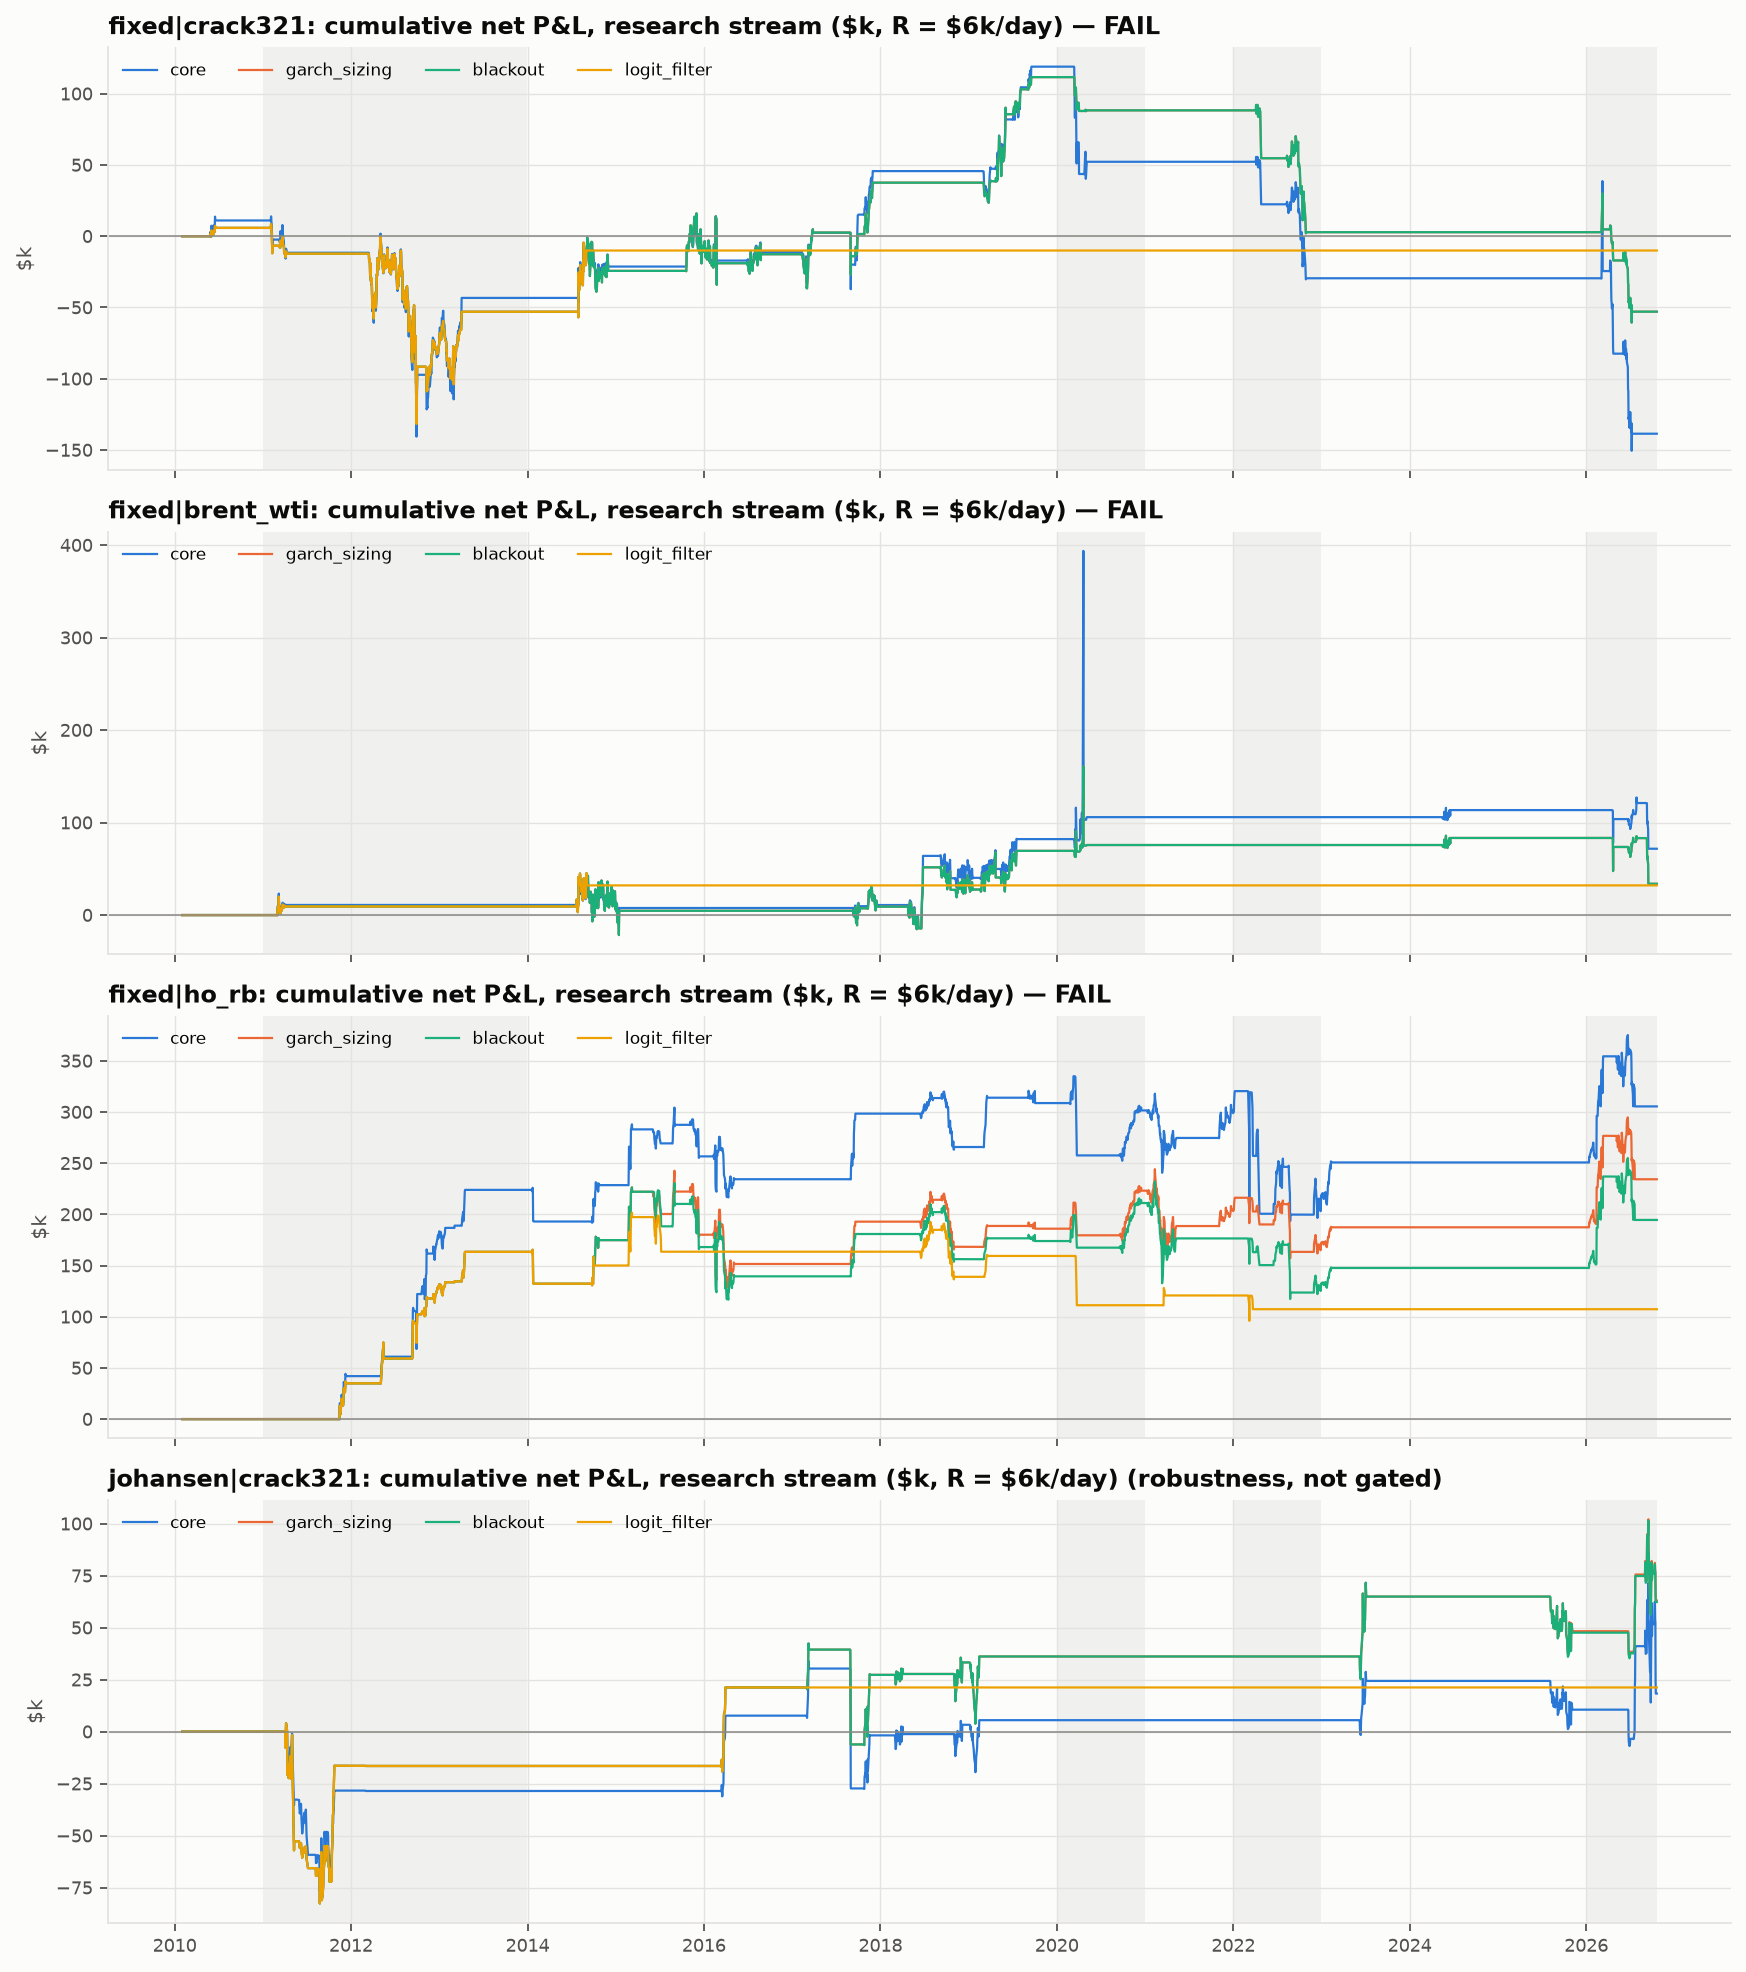

In [4]:
Image(str(F / '06_cumulative_pnl.png'))

**Reading the ladder**
- **GARCH sizing** (core → + garch) improves every spread's Sharpe and cuts the worst drawdowns. The crack's max drawdown falls from \$270k to \$172k, and Brent–WTI's from \$322k to \$127k.
  - Most of the core step's damage comes from sizing on a window sd inflated by April 2020. The Brent–WTI core curve spikes to +\$390k on 20 Apr 2020 and gives it back the next day.
- **The blackout binds rarely, and here it hurts.** It moves two HO−RB entries off the eve of OPEC meetings (June 2015 and November 2021). The second was a \$27.7k winner, so HO−RB's Sharpe falls from 0.32 to 0.27. (Before the code-review fix, the blackout was applied to the decision day instead of the fill day and never bound; see the report's Appendix C.)
- **The logit filter mainly removes trades.**
  - Crack: 26 → 6 trades. Brent–WTI: 18 → 2. HO−RB: 33 → 19.
  - After 2015 it almost never lets the crack or Brent–WTI trade (Part 5 found P ≥ 0.6 on only 3–4% of days).
  - It raises the crack's and Brent–WTI's Sharpe by cutting exposure, not by picking better trades. For HO−RB it lowers the Sharpe (0.27 → 0.25).
- **Without the filter, HO−RB is the only spread with a consistently positive edge:** Sharpe 0.27 (t = 1.1), 59% wins, \$195k over 16.7 years at R = \$6k a day. 84% of it was made in 2010–13.
- **Without the filter, the crack loses in both 2020–26 and 2010–13.** Stop-losses are the most common exit (11 of 26 trades). This is the plan's "fading the 2026 crack would have hurt", seen in the data.

In [5]:
read('06_exit_reasons.csv', index_col=0)

,fixed|crack321|blackout,fixed|crack321|logit_filter,fixed|brent_wti|blackout,fixed|brent_wti|logit_filter,fixed|ho_rb|blackout,fixed|ho_rb|logit_filter,johansen|crack321|blackout,johansen|crack321|logit_filter
exit_reason,,,,,,,,
model_break,1,0,1,0,0,0,4,1
regime_break,0,1,0,1,0,2,0,0
stop_loss,11,2,3,0,10,6,5,2
take_profit,10,2,6,0,14,8,7,2
time_stop,4,1,8,1,8,3,4,1


In [6]:
read('06_subperiods.csv', index_col=[0, 1]).round(1)

net  sharpe    days
run                            period                             
fixed|crack321|blackout        2007–2013  -53041.3    -0.3   936.0
                               2014–2019  164644.4     0.5  1486.0
                               2020–2026 -164562.1    -0.9  1669.0
fixed|crack321|logit_filter    2007–2013  -53041.3    -0.3   936.0
                               2014–2019   42987.7     0.4  1486.0
                               2020–2026       0.0     NaN  1669.0
fixed|brent_wti|blackout       2007–2013    9322.6     0.3   936.0
                               2014–2019   60073.5     0.2  1486.0
                               2020–2026  -35607.1    -0.1  1669.0
fixed|brent_wti|logit_filter   2007–2013    9322.6     0.3   936.0
                               2014–2019   22742.9     0.2  1486.0
                               2020–2026       0.0     NaN  1669.0
fixed|ho_rb|blackout           2007–2013  163345.0     1.4   936.0
                               2014–2019   10584.4     0.0  1486.0
                               2020–2026   20629.1     0.1  1669.0
fixed|ho_rb|logit_filter       2007–2013  163345.0     1.4   936.0
                               2014–2019   -3969.1    -0.0  1486.0
                               2020–2026  -52039.0    -0.4  1669.0
johansen|crack321|blackout     2007–2013  -16518.8    -0.1   936.0
                               2014–2019   52651.6     0.4  1486.0
                               2020–2026   26174.0     0.1  1669.0
johansen|crack321|logit_filter 2007–2013  -16518.8    -0.1   936.0
                               2014–2019   37758.2     0.8  1486.0
                               2020–2026       0.0     NaN  1669.0

## Stress windows (G5 uses 2022 and 2026)

In [7]:
read('06_stress_windows.csv', index_col=[0, 1]).round(0)

filtered  unfiltered  filtered_trades  unfiltered_trades
window          key                                                                        
brent_wti_break fixed|crack321     -58851.0    -58851.0              4.0                4.0
                fixed|brent_wti      9323.0      9323.0              1.0                1.0
                fixed|ho_rb        163345.0    163345.0              8.0                8.0
                johansen|crack321  -16519.0    -16519.0              5.0                5.0
covid           fixed|crack321          0.0    -23301.0              0.0                4.0
                fixed|brent_wti         0.0      6322.0              0.0                3.0
                fixed|ho_rb        -48155.0     37143.0              1.0                3.0
                johansen|crack321       0.0         0.0              0.0                0.0
ukraine         fixed|crack321          0.0    -85506.0              0.0                2.0
                fixed|brent_wti         0.0         0.0              0.0                0.0
                fixed|ho_rb        -13452.0    -44133.0              2.0                6.0
                johansen|crack321       0.0         0.0              0.0                0.0
hormuz          fixed|crack321          0.0    -55755.0              0.0                3.0
                fixed|brent_wti         0.0    -49555.0              0.0                4.0
                fixed|ho_rb             0.0     46931.0              0.0                2.0
                johansen|crack321       0.0     14723.0              0.0                5.0

- **The filter kept the crack and Brent–WTI completely flat in 2022 and 2026.** It avoided −\$86k (crack, 2022), −\$56k (crack, 2026) and −\$50k (Brent–WTI, 2026). That is the "stay out of the war regime" behaviour the plan wanted.
- **But it also kept HO−RB out of a profitable 2026** (+\$47k unfiltered), so HO−RB fails G5.
- **In 2020 the filter let one losing HO−RB trade through** (−\$48k) while the unfiltered book made \$37k there.

## Pre-registered robustness

In [8]:
g = read('06_entry_exit_grid.csv', index_col=[0, 1, 2])
g['sharpe'].unstack(0).round(3)

key             fixed|brent_wti  fixed|crack321  fixed|ho_rb  johansen|crack321
entry_z exit_z                                                                 
1.5     0.25              0.123           0.160        0.572              0.015
        0.50              0.192           0.301        0.628              0.017
        0.75              0.267           0.275        0.560              0.118
2.0     0.25              0.128          -0.044        0.218              0.059
        0.50              0.128          -0.022        0.254              0.071
        0.75              0.128          -0.039        0.246             -0.015
2.5     0.25             -0.083          -0.086        0.132              0.077
        0.50             -0.083          -0.080        0.223              0.087
        0.75              0.004          -0.099        0.218              0.056

In [9]:
g['n_trades'].unstack(0)

key             fixed|brent_wti  fixed|crack321  fixed|ho_rb  johansen|crack321
entry_z exit_z                                                                 
1.5     0.25                7.0            10.0         34.0                5.0
        0.50                8.0            10.0         36.0                5.0
        0.75                8.0            10.0         36.0                6.0
2.0     0.25                2.0             6.0         18.0                6.0
        0.50                2.0             6.0         19.0                6.0
        0.75                2.0             6.0         19.0                6.0
2.5     0.25                3.0             7.0         14.0                4.0
        0.50                3.0             7.0         15.0                4.0
        0.75                3.0             7.0         15.0                4.0

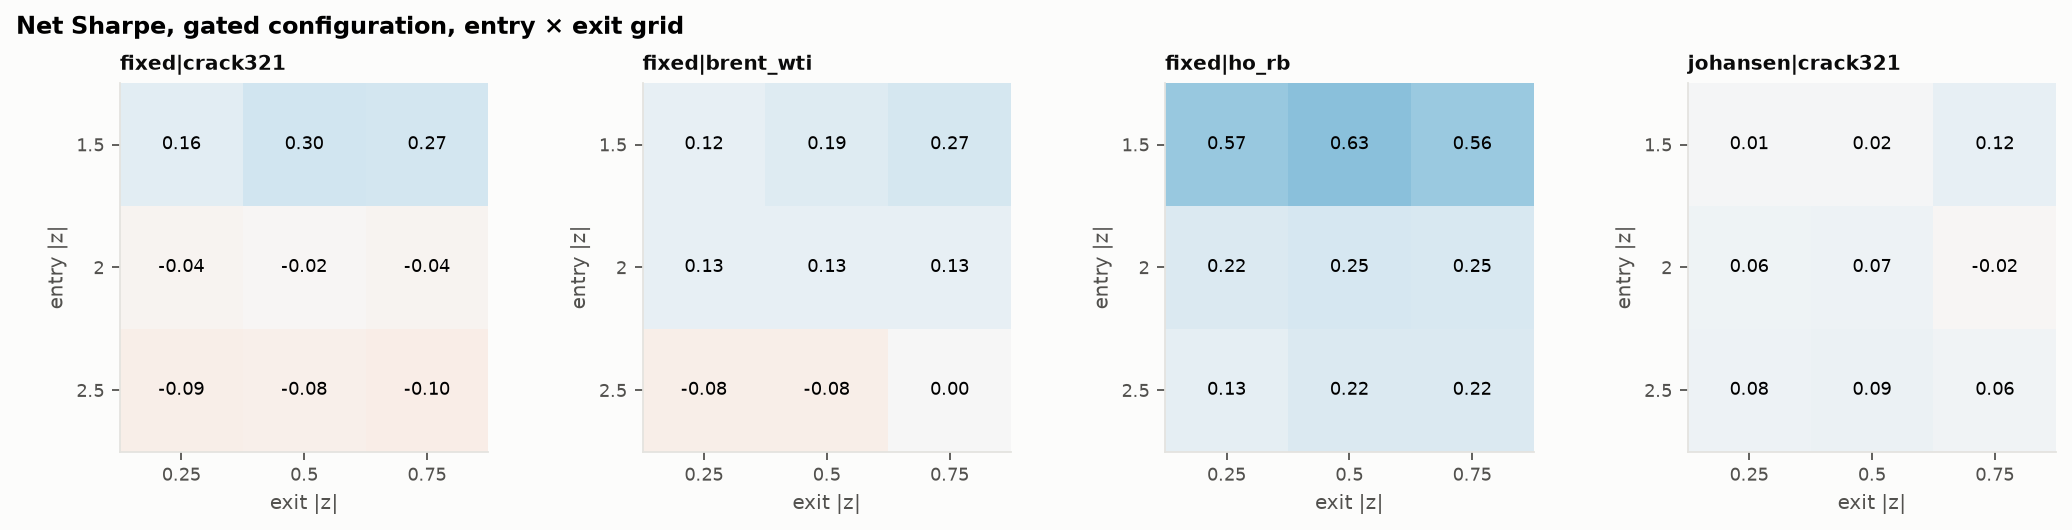

In [10]:
Image(str(F / '06_entry_exit_grid.png'))

In [11]:
read('06_cost_sweep.csv', index_col=[0, 1])['sharpe'].unstack(0).round(3)

key,fixed|brent_wti,fixed|crack321,fixed|ho_rb,johansen|crack321
cost_usd_per_bbl,,,,
0.000,0.132,-0.017,0.269,0.076
0.025,0.130,-0.019,0.261,0.073
0.050,0.128,-0.022,0.254,0.071
0.100,0.124,-0.026,0.240,0.065
0.200,0.117,-0.034,0.211,0.055


In [12]:
r = read('06_robustness.csv', index_col=[0, 1])
r[['sharpe', 'sharpe_t', 'total', 'n_trades', 'max_dd']].round(3)

sharpe  sharpe_t       total  n_trades      max_dd
run                              key                                                                  
window 504                       fixed|crack321      0.010     0.043    4993.165      12.0 -164300.159
                                 fixed|brent_wti    -0.003    -0.013    -612.370       9.0  -29041.466
                                 fixed|ho_rb         0.093     0.385   46229.367      35.0  -79054.635
                                 johansen|crack321   0.097     0.402   31474.149       9.0  -49913.317
window 1008                      fixed|crack321      0.019     0.074   11189.684      10.0 -176701.143
                                 fixed|brent_wti     0.317     1.238  162743.144      14.0  -72122.692
                                 fixed|ho_rb         0.211     0.824   97598.429      22.0 -106438.461
                                 johansen|crack321   0.036     0.141   11094.316       6.0  -80847.774
label 10d                        fixed|crack321     -0.021    -0.086  -12658.280       9.0 -140210.268
                                 fixed|brent_wti     0.024     0.096   10862.469       5.0  -66819.905
                                 fixed|ho_rb         0.266     1.072  138723.645      16.0 -113895.017
                                 johansen|crack321   0.071     0.285   21239.390       6.0  -86674.458
label 40d                        fixed|crack321     -0.015    -0.062   -7451.608      10.0 -140210.268
                                 fixed|brent_wti     0.015     0.058    5690.875      10.0  -71066.205
                                 fixed|ho_rb         0.238     0.958  145751.782      27.0 -133888.653
                                 johansen|crack321   0.088     0.353   31323.561      10.0  -86674.458
drop Apr 2020 week, blackout     fixed|crack321     -0.106    -0.427  -88544.363      31.0 -216781.512
drop Apr 2020 week, logit_filter fixed|crack321     -0.042    -0.168  -20024.674       8.0 -140210.268
drop Apr 2020 week, blackout     fixed|brent_wti     0.145     0.585  109058.110      23.0  -66819.905
drop Apr 2020 week, logit_filter fixed|brent_wti     0.236     0.949   67760.856       3.0  -28915.039
drop Apr 2020 week, blackout     fixed|ho_rb         0.318     1.279  224473.989      32.0 -113895.017
drop Apr 2020 week, logit_filter fixed|ho_rb         0.251     1.010  105788.332      19.0 -105034.250
drop Apr 2020 week, blackout     johansen|crack321   0.066     0.266   38895.004      30.0  -95009.902
drop Apr 2020 week, logit_filter johansen|crack321   0.071     0.285   21239.390       6.0  -86674.458
base (gated config)              fixed|crack321     -0.022    -0.087  -10053.546       6.0 -140210.268
base, no logit (blackout step)   fixed|crack321     -0.074    -0.298  -52958.935      26.0 -172248.545
base (gated config)              fixed|brent_wti     0.128     0.517   32065.552       2.0  -28915.039
base, no logit (blackout step)   fixed|brent_wti     0.040     0.163   33788.999      18.0 -126832.129
base (gated config)              fixed|ho_rb         0.254     1.024  107336.865      19.0 -105628.244
base, no logit (blackout step)   fixed|ho_rb         0.270     1.089  194558.466      32.0 -114778.920
base (gated config)              johansen|crack321   0.071     0.285   21239.390       6.0  -86674.458
base, no logit (blackout step)   johansen|crack321   0.134     0.539   62306.891      20.0  -86674.458

- **Entry grid:** only HO−RB keeps a positive Sharpe at every entry |z|: 0.63 / 0.25 / 0.22 at 1.5 / 2 / 2.5. That is G4 ✓. Its entry-1.5 row (0.56–0.63 across the three exit levels, 34–36 trades) holds the only grid points above 0.5 anywhere. Choosing it after the fact would be exploratory.
- **Costs matter little.** Trades are rare. At \$0.20/bbl a side (four times the base cost), HO−RB's Sharpe falls from 0.27 (zero cost) to 0.21, and the others move by 0.02 or less.
- **Window length:**
  - 504 days removes most of the edge (HO−RB 0.09; the others about 0).
  - 1008 days helps Brent–WTI (0.32) and HO−RB (0.21).
  - Nothing reaches 0.5.
- **Label horizon:** the 10- and 40-day labels leave the crack about where it was, and lower HO−RB slightly (0.27 and 0.24). Both take Brent–WTI's Sharpe to about 0.
- **Dropping the April 2020 week** (pre-registered robustness) helps Brent–WTI (0.13 → 0.24 with the filter, 0.04 → 0.15 without) and HO−RB without the filter (0.32). No gate would change.

## Integer book (\$2m, worked-example sizing, drawdown rules)

In [13]:
read('06_integer_book.csv', index_col=0)

,final_equity,total,sharpe,max_dd_usd,max_drawdown_pct,halted,n_trades,blocked_by_size,days_half_size
gated,2036822.0,36822.0,0.074580,-78946.0,0.038560,False,24,29,0
no logit,2127386.0,127386.0,0.091926,-301442.0,0.124612,False,62,200,1097


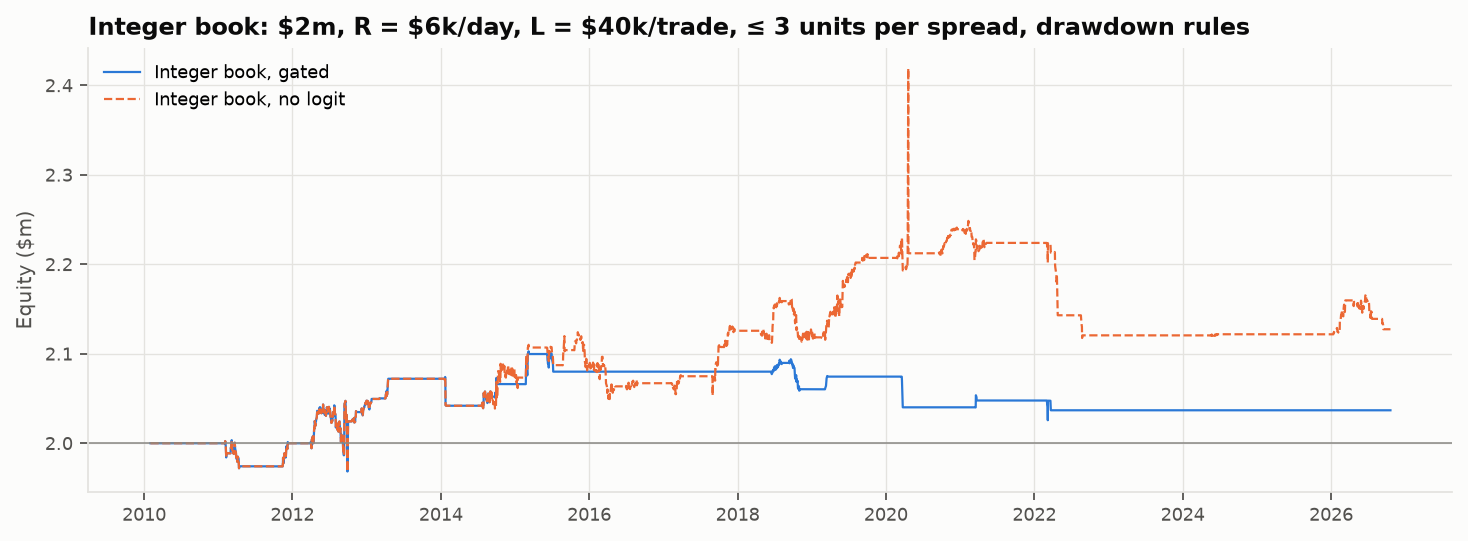

In [14]:
Image(str(F / '06_integer_book.png'))

- **Whole contracts and the stop limit shrink the book a lot.** The plan's worked example B shows up in the data: in volatile regimes the size rule gives 0 units. The size rule blocked an otherwise valid entry on 200 signal-days without the logit, and 29 with it.
- **Gated book:** +\$37k over 16.7 years on \$2m (Sharpe 0.07). It has not traded since 2022.
- **Without the logit:**
  - +\$127k, with a maximum drawdown of 12.5%.
  - That drawdown triggered the halving rule, so the book ran at half size for 1,097 days, from April 2022 to date.
  - It never reached the 20% stop.

## Conclusion (spot proxy)
- **Every spread fails.** The pre-registered strategy does not pass on any spread.
- **The regime filter has no forecasting skill** (Part 5). In practice it is an off switch: it kept the book out of the 2022 and 2026 dislocations, and out of most other periods too.
- **The one durable signal is HO−RB without the filter:** Sharpe 0.27, positive in all three sub-periods (and, gated, at every entry threshold). It is still statistically weak (t ≈ 1.1), and 84% of the profit comes from 2010–13.
- **What the binding futures run decides:**
  - whether the futures spreads, which have no NYH gasoline-grade switches and no negative-WTI print in the held contract, change this picture
  - whether the filter fares better on futures
- Any rule change motivated by these results (for example dropping the logit, or trading HO−RB at entry 1.5) would be **exploratory**, reported separately, and could not claim a gate pass.